In [5]:
# 도미 및 빙어 길이와 무게 데이터를 각각 리스트로 저장한다.

bream_length = [
    25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7,
    30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0,
    32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0,
    34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0,
    36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0
]

bream_weight = [
    242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0,
    390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0,
    600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0,
    685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0,
    850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0
]

smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8,
    11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0
]

smelt_weight = [
    6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0,
    9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9
]

In [3]:
# 도미와 빙어의 길이 데이터를 하나의 리스트로 합친다.
# 도미와 빙어의 무게 데이터를 하나의 리스트로 합친다.

length = bream_length + smelt_length
weight = bream_weight + smelt_weight

print (length), print (weight)
print (len(length))
print (len(weight))

[25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
[242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]
49
49


In [12]:
#데이터의 타깃을
import numpy as np

fish_data = np.column_stack((length,weight))
fish_target = np.concatenate((np.ones(35),np.zeros(14)))
print(len(length),len(weight))
print(fish_data[15])
print(fish_target)


49 49
[ 32. 600.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


In [14]:
#훈련데이터와 타깃데이터를 나눈다
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(
    fish_data,
    fish_target,
    random_state=42
)

print(train_input.shape, test_input.shape)
print(train_target.shape, test_target.shape)
print(test_target)

(36, 2) (13, 2)
(36,) (13,)
[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [19]:
# 최근접 이웃
# 2시 34분 사진에 값넣기

from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()

# 훈련
kn.fit(train_input, train_target)

print(kn.score(train_input, train_target)) #훈련데이터의 점수
print(kn.score(test_input, test_target))    #테스트 데이터의 점수



1.0
1.0


In [25]:
#샘플평가하기
one = np.array([[25,150]])
distances, idx = kn.kneighbors(one)
print(kn.predict(one), kn.predict_proba(one))
kn.kneighbors(one)  #one과의 이웃으 정보(거리, 인덱스)

[0.] [[0.6 0.4]]


(array([[ 92.00086956, 130.48375378, 138.32150953, 140.00603558,
         140.62090883]]),
 array([[12, 29,  5, 19,  4]]))

AttributeError: PathCollection.set() got an unexpected keyword argument 'markers'

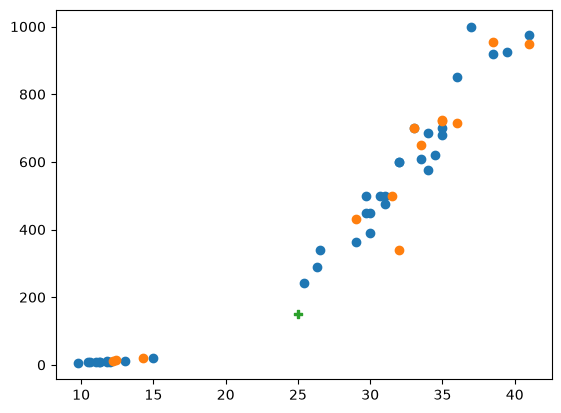

In [26]:
#훈련데이터 테스트데이터 샘플 샘플의 이웃을
import matplotlib.pyplot as plt

plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(test_input[:,0], test_input[:,1])

plt.scatter(one[0,0],one[0,1],marker='P')
plt.scatter(train_input[idx,0],train_input[idx,1],markers = "`")